# Linear sum vs dynamic runs (2013)

The **method error**: the bulk metamodel (linear sum, MDA 600, CODEC) against SnapWave run
every hour with all goals, CODEC and no wind (same bulk forcing), at every output site
(isobaths 5 / 10 / 20 m, Den Haag nodes, buoys). Then the spectral metamodel against the
same runs: what summing partitions instead of bulk sea states changes. Reference = dynamic run.

In [ ]:
import sys

sys.path.insert(0, "..")  # the case folder (utils/)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import results as rs
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

In [ ]:
SETS = ("isobaths", "deenhaag", "buoys")
fields = {}
for off in rs.OFFSHORE:
    for st in SETS:
        bulk = rs.metamodel(off, st, False)
        spec = rs.metamodel(off, st, True)
        dyn = rs.dynamic(off, False, bulk.sites.values).reindex(time=bulk.time)
        fields[off, st] = {
            "bulk": bulk,
            "spectral": spec,
            "dynamic": rs.attach_site_meta(dyn),
        }
print({k: v["bulk"].sizes["sites"] for k, v in fields.items()})

{('WHACS', 'isobaths'): 4977, ('WHACS', 'deenhaag'): 141, ('WHACS', 'buoys'): 38, ('WHACS_cal', 'isobaths'): 4977, ('WHACS_cal', 'deenhaag'): 141, ('WHACS_cal', 'buoys'): 38}


## 1 · Per site group, every variable

Metrics pooled over all pairs of each group (direction circular).

In [ ]:
for (off, st), f in fields.items():
    for name in ("bulk", "spectral"):
        rows = []
        for variable in rs.VARIABLES:
            g = rs.group_metrics(f["dynamic"], f[name], variable)
            rows.append(
                g[["sites", "n", "bias", "rmse", "r2"]].assign(variable=variable)
            )
        print(f"{off} · {st} · {name} metamodel vs dynamic no wind")
        display(pd.concat(rows).set_index("variable", append=True))

WHACS · isobaths · bulk metamodel vs dynamic no wind


,,sites,n,bias,rmse,r2
,variable,,,,,
5m,hs,1175,10293000,0.034,0.155,0.893
10m,hs,1875,16425000,0.010,0.139,0.926
20m,hs,1927,16880520,-0.015,0.149,0.937
5m,tp,1175,10291570,-0.037,1.291,0.455
10m,tp,1875,16423781,-0.186,1.372,0.385
20m,tp,1927,16878216,-0.136,1.314,0.436
5m,dir,1175,10293000,-0.199,18.399,0.809
10m,dir,1875,16425000,0.110,18.525,0.824
20m,dir,1927,16880520,-0.149,16.919,0.877


WHACS · isobaths · spectral metamodel vs dynamic no wind


,,sites,n,bias,rmse,r2
,variable,,,,,
5m,hs,1175,10293000,0.138,0.227,0.769
10m,hs,1875,16425000,0.075,0.172,0.886
20m,hs,1927,16880520,0.029,0.166,0.922
5m,tp,1175,10292836,1.718,3.589,-3.208
10m,tp,1875,16424336,0.932,3.029,-1.997
20m,tp,1927,16879342,0.491,2.512,-1.062
5m,dir,1175,10293000,3.333,31.819,0.428
10m,dir,1875,16425000,2.748,29.747,0.545
20m,dir,1927,16880520,3.647,26.209,0.705


WHACS · deenhaag · bulk metamodel vs dynamic no wind


sites        n   bias    rmse     r2
         variable                                      
DeenHaag hs          141  1235160 -0.008   0.132  0.934
         tp          141  1235092 -0.219   1.295  0.453
         dir         141  1235160  0.158  18.176  0.825
         spr         141  1235092  0.582   7.330  0.227

... (14 outputs left out)

WHACS_cal · buoys · bulk metamodel vs dynamic no wind


sites       n   bias    rmse     r2
      variable                                     
waves hs           38  332880 -0.003   0.142  0.943
      tp           38  332851 -0.234   1.402  0.358
      dir          38  332880  0.161  17.799  0.852
      spr          38  332851 -0.322   6.482  0.299

WHACS_cal · buoys · spectral metamodel vs dynamic no wind


sites       n   bias    rmse     r2
      variable                                     
waves hs           38  332880  0.047   0.156  0.932
      tp           38  332868  0.352   2.339 -0.786
      dir          38  332880  3.800  25.894  0.687
      spr          38  332880  4.916  11.070 -1.042

## 2 · Maps of the method error

Per-site Hs bias and RMSE of the bulk metamodel against the dynamic run (isobaths).

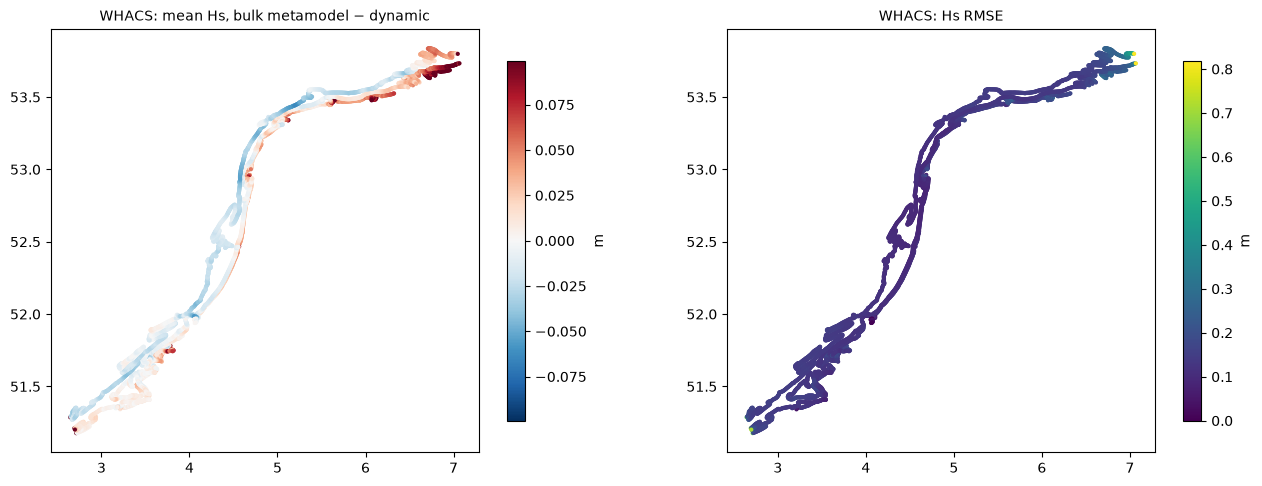

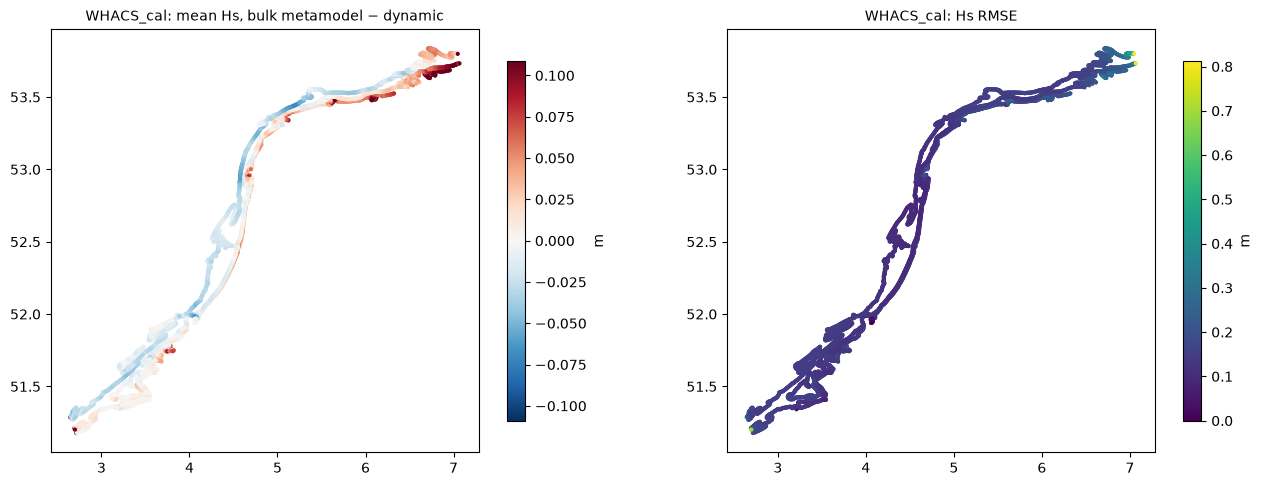

In [ ]:
for off in rs.OFFSHORE:
    f = fields[off, "isobaths"]
    d = f["bulk"]["hs"] - f["dynamic"]["hs"]
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    rs.plot_site_map(
        d.mean("time").assign_coords(f["bulk"]["hs"].isel(time=0, drop=True).coords),
        f"{off}: mean Hs, bulk metamodel − dynamic",
        "m",
        ax=axes[0],
    )
    rs.plot_site_map(
        np.sqrt((d**2).mean("time")).assign_coords(
            f["bulk"]["hs"].isel(time=0, drop=True).coords
        ),
        f"{off}: Hs RMSE",
        "m",
        cmap="viridis",
        vmin=0,
        ax=axes[1],
    )
    plt.show()

## 3 · Method error by sea state

Hs difference (bulk metamodel − dynamic) by each site's own Hs quantile class (classes from
the dynamic run), per isobath.

In [ ]:
for off in rs.OFFSHORE:
    f = fields[off, "isobaths"]
    d = f["bulk"]["hs"] - f["dynamic"]["hs"]
    classes = rs.rank_classes(rs.hs_rank(f["dynamic"]))
    for label in ("5m", "10m", "20m"):
        sel = f["bulk"]["site_label"].values == label
        print(f"{off} · {label}")
        display(
            rs.by_class(
                d.isel(sites=sel),
                classes.isel(sites=sel),
                ["p0-50", "p50-90", "p90-99", "p99-100"],
            )
        )

WHACS · 5m


,mean,rmse,p10,p90,n
c,,,,,
p0-50,0.031,0.128,-0.107,0.174,5146500
p50-90,0.014,0.137,-0.140,0.168,4117200
p90-99,0.099,0.227,-0.114,0.350,925899
p99-100,0.438,0.609,0.030,1.040,103401


WHACS · 10m


,mean,rmse,p10,p90,n
c,,,,,
p0-50,0.019,0.138,-0.120,0.160,8212500
p50-90,-0.010,0.128,-0.153,0.129,6569999
p90-99,0.033,0.159,-0.155,0.202,1477501
p99-100,0.170,0.318,-0.095,0.444,165000


WHACS · 20m


,mean,rmse,p10,p90,n
c,,,,,
p0-50,-0.004,0.147,-0.147,0.130,8440259
p50-90,-0.035,0.152,-0.179,0.103,6752209
p90-99,-0.002,0.140,-0.156,0.158,1518476
p99-100,0.077,0.184,-0.101,0.276,169576


... (2 outputs left out)

WHACS_cal · 10m


,mean,rmse,p10,p90,n
c,,,,,
p0-50,0.017,0.138,-0.123,0.159,8212500
p50-90,-0.011,0.130,-0.155,0.130,6570000
p90-99,0.040,0.169,-0.151,0.214,1477500
p99-100,0.287,0.505,-0.061,0.797,165000


WHACS_cal · 20m


,mean,rmse,p10,p90,n
c,,,,,
p0-50,-0.008,0.147,-0.151,0.128,8440259
p50-90,-0.038,0.155,-0.184,0.102,6752208
p90-99,-0.007,0.143,-0.162,0.155,1518477
p99-100,0.113,0.215,-0.087,0.358,169576
